# UniProt annotation omics - exploratory and statistical analysis

The pipelines in `src/pipelines/uniprot/` parse the downloaded
**UniProtKB/Swiss-Prot** flat file (`rawdata/UniProt/uniprot_sprot.dat`) and
integrate curated protein annotations into MySQL **COMPLEX2**.

Data used in this notebook:

| pipeline step | script (`bomics <cmd>`) | SQL table | content |
|---|---|---|---|
| entry registry | `uniprot` | `uniprot` | accession, name, organism, sequence, dates |
| keywords | `uniprot_keyword` | `uniprot_keyword` | curated functional keyword |
| features | `uniprot_feature` | `uniprot_feature` | feature type, coordinates, note |
| cross-references | `uniprot_dbxrefs` | `uniprot_dbxrefs` | links to GO, Pfam, PDB, AlphaFoldDB ... |
| sequences | `uniprot_proseq` | `uniprot_proseq` | protein sequence/length |

**Outputs**
- figures -> `doc/figures/uniprot_*.png`
- statistical tables -> `doc/stats/uniprot_*.csv` (ready for further analysis)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def _locate_doc_dir():
    for start in (Path.cwd(), *Path.cwd().parents):
        if (start / 'doc' / 'nb_utils.py').is_file():
            return start / 'doc'
    return Path.cwd()

doc_dir = _locate_doc_dir()
sys.path.insert(0, str(doc_dir))
from nb_utils import (query_df, query_scalar, save_fig, save_csv,
                      describe_groups, pairwise_mannwhitney,
                      FIG_DIR, STAT_DIR, PALETTE)

print('figures ->', FIG_DIR)
print('stats   ->', STAT_DIR)

figures -> /home/yuan/bio/bio_omics/doc/figures
stats   -> /home/yuan/bio/bio_omics/doc/stats


## 1. Output inventory

In [2]:
tables = ['uniprot', 'uniprot_keyword', 'uniprot_feature',
          'uniprot_dbxrefs', 'uniprot_proseq']
inventory = pd.DataFrame(
    [{'table': t, 'n_records': query_scalar(f'SELECT COUNT(*) AS n FROM {t}')}
     for t in tables])
inventory['n_records'] = inventory['n_records'].astype(int)
save_csv(inventory, 'uniprot_table_inventory')
inventory

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_table_inventory.csv  shape=(5, 2)


,table,n_records
0,uniprot,575503
1,uniprot_keyword,3881913
2,uniprot_feature,5829810
3,uniprot_dbxrefs,21839180
4,uniprot_proseq,575503


## 2. Growth of the curated proteome

`uniprot.creation_date` is the date an entry entered Swiss-Prot. The growth
curve reflects how much curated protein knowledge exists per year - the
backbone for annotation transfer, BLAST databases and machine-learning sets.

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_creation_by_year.csv  shape=(41, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_creation_trend.png
span: 1986 -> 2026, total 575,503 entries


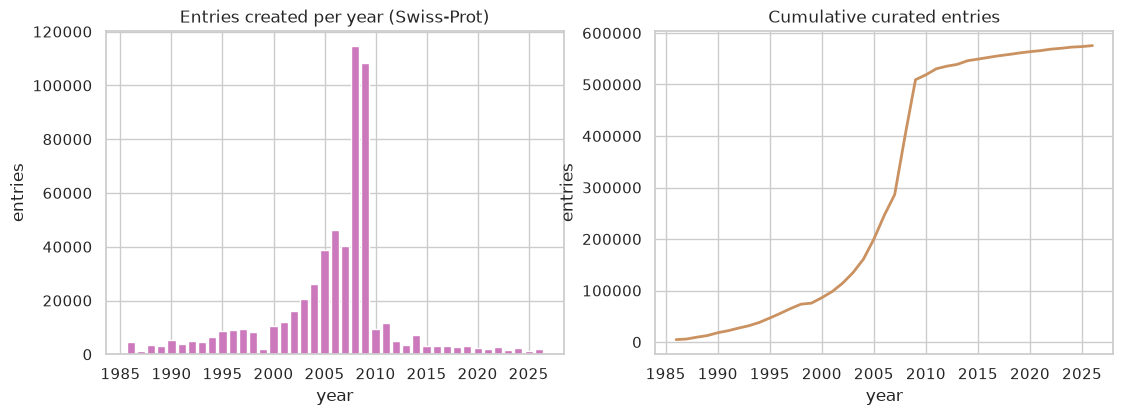

In [3]:
yearly = query_df("""
    SELECT YEAR(creation_date) AS year, COUNT(*) AS n_entries
    FROM uniprot
    WHERE creation_date IS NOT NULL
    GROUP BY year
    ORDER BY year
""")
yearly['year'] = yearly['year'].astype(int)
yearly['n_entries'] = yearly['n_entries'].astype(int)
yearly['cum_entries'] = yearly['n_entries'].cumsum()
save_csv(yearly, 'uniprot_creation_by_year')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(yearly['year'], yearly['n_entries'], color=PALETTE[4])
ax[0].set_title('Entries created per year (Swiss-Prot)')
ax[0].set_xlabel('year')
ax[0].set_ylabel('entries')
ax[1].plot(yearly['year'], yearly['cum_entries'], color=PALETTE[5], lw=2)
ax[1].set_title('Cumulative curated entries')
ax[1].set_xlabel('year')
ax[1].set_ylabel('entries')
save_fig(fig, 'uniprot_creation_trend')
print(f"span: {yearly['year'].min()} -> {yearly['year'].max()}, "
      f"total {yearly['n_entries'].sum():,} entries")

## 3. Organism representation

Swiss-Prot curation is focused: fully sequenced model organisms and medically
important species receive the deepest annotation. Ranking entries per organism
shows which proteomes dominate the curated space - the set of organisms any
cross-species comparison will lean on.

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_top_organisms.csv  shape=(30, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_top_organisms.png


,organism,n_entries,fraction
0,Homo sapiens (Human),20431,0.035501
1,Mus musculus (Mouse),17267,0.030003
2,Arabidopsis thaliana (Mouse-ear cress),16419,0.028530
3,Rattus norvegicus (Rat),8232,0.014304
4,Saccharomyces cerevisiae (strain ATCC 204508 /...,6733,0.011699
5,Bos taurus (Bovine),6053,0.010518
6,Schizosaccharomyces pombe (strain 972 / ATCC 2...,5129,0.008912
7,Escherichia coli (strain K12),4531,0.007873
8,Caenorhabditis elegans,4488,0.007798
9,Oryza sativa subsp. japonica (Rice),4197,0.007293


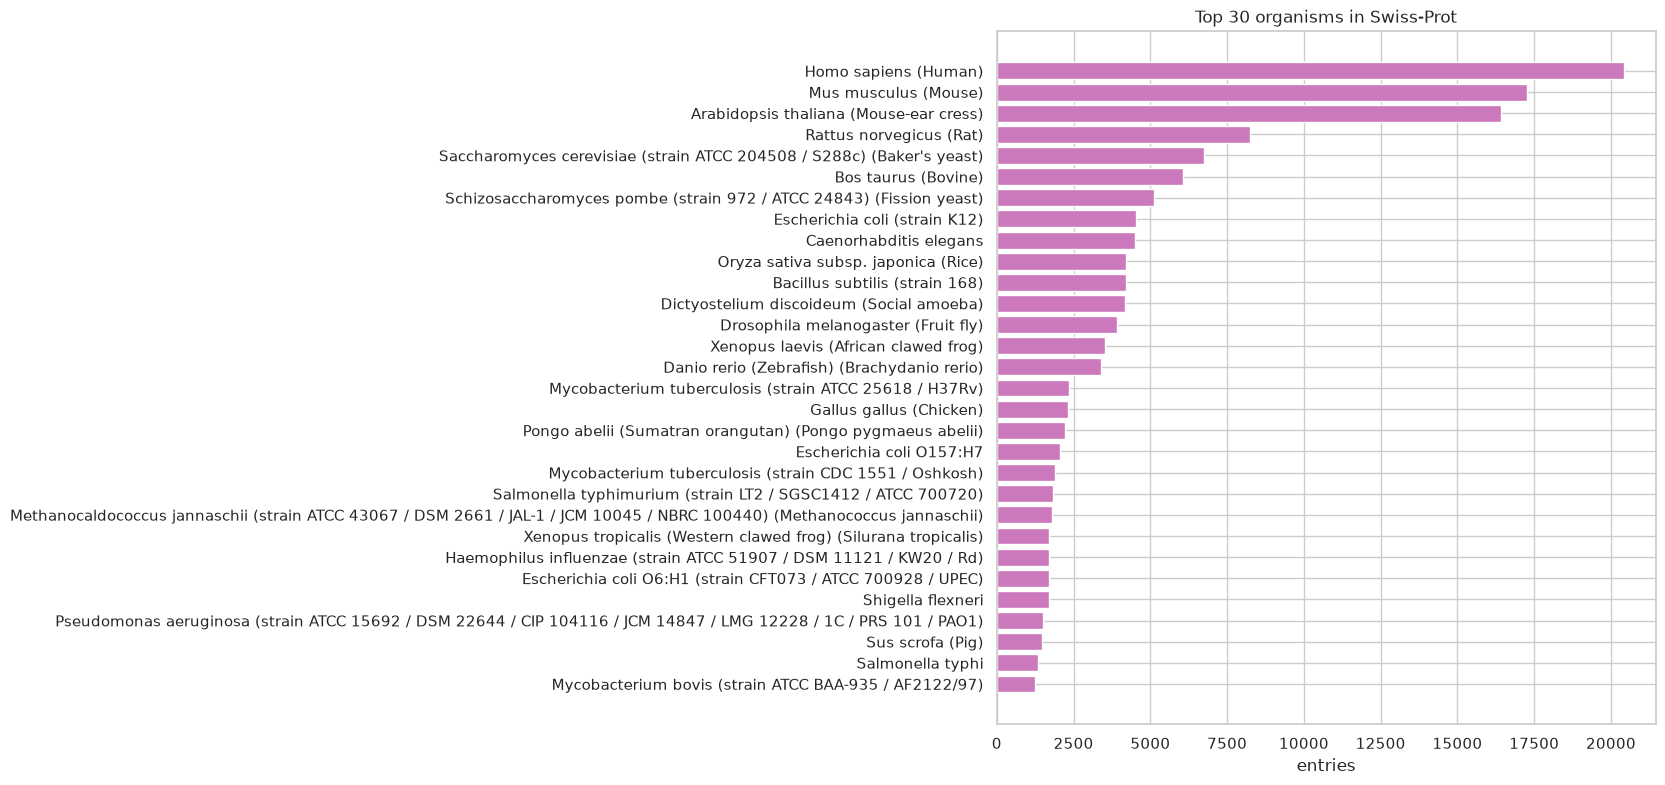

In [4]:
organisms = query_df("""
    SELECT organism, COUNT(*) AS n_entries
    FROM uniprot
    WHERE organism IS NOT NULL
    GROUP BY organism
    ORDER BY n_entries DESC
    LIMIT 30
""")
organisms['n_entries'] = organisms['n_entries'].astype(int)
total = query_scalar('SELECT COUNT(*) AS n FROM uniprot')
organisms['fraction'] = organisms['n_entries'] / total
save_csv(organisms, 'uniprot_top_organisms')

fig, ax = plt.subplots(figsize=(8.5, 9))
ax.barh(organisms['organism'].iloc[::-1], organisms['n_entries'].iloc[::-1],
        color=PALETTE[4])
ax.set_title('Top 30 organisms in Swiss-Prot')
ax.set_xlabel('entries')
save_fig(fig, 'uniprot_top_organisms')
organisms.head(10)

## 4. Protein length - Swiss-Prot versus crystallized chains

`uniprot.pro_len` (a generated column over `pro_seq`) describes the *complete*
canonical protein, whereas `pdb_chain_seq.pro_len` describes cloned constructs
actually crystallized. A two-sample Kolmogorov-Smirnov test quantifies how the
structural archive is shifted towards shorter chains - a direct measurement of
the construct-design bias of structural biology.

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_length_stats.csv  shape=(1, 9)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_protein_length.png


,source,n,mean,std,q25,median,q75,q95,max
0,uniprot_swissprot,575503,362.998806,345.024674,169.0,296.0,451.0,879.0,35213


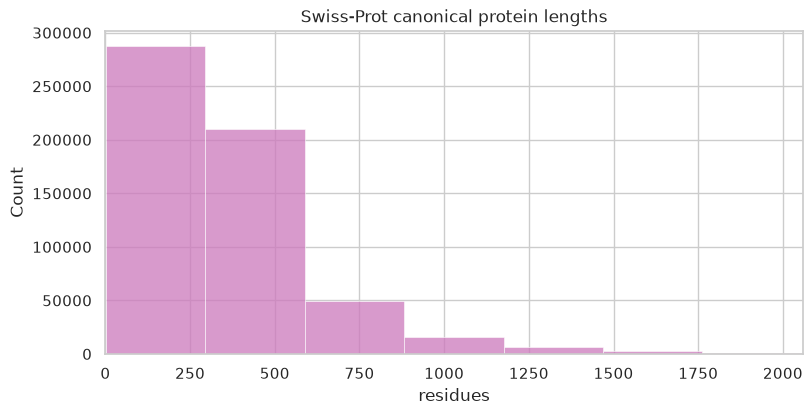

In [5]:
uni_len = query_df('SELECT pro_len FROM uniprot WHERE pro_len IS NOT NULL')
uni_lens = uni_len['pro_len'].astype(int)

uni_summ = pd.DataFrame([{
    'source': 'uniprot_swissprot', 'n': len(uni_lens),
    'mean': uni_lens.mean(), 'std': uni_lens.std(),
    'q25': uni_lens.quantile(0.25), 'median': uni_lens.median(),
    'q75': uni_lens.quantile(0.75), 'q95': uni_lens.quantile(0.95),
    'max': uni_lens.max(),
}])
save_csv(uni_summ, 'uniprot_length_stats')

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(uni_lens, bins=120, ax=ax, color=PALETTE[4])
ax.set_xlim(0, uni_lens.quantile(0.995))
ax.set_title('Swiss-Prot canonical protein lengths')
ax.set_xlabel('residues')
save_fig(fig, 'uniprot_protein_length')
uni_summ

saved table: /home/yuan/bio/bio_omics/doc/stats/protein_length_comparison.csv  shape=(2, 9)
saved table: /home/yuan/bio/bio_omics/doc/stats/protein_length_tests.csv  shape=(2, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/protein_length_pdb_vs_uniprot.png
              test    statistic  p_value
kolmogorov-smirnov 2.788677e-01      0.0
    mann-whitney-u 1.840170e+11      0.0


,source,n,mean,std,q25,median,q75,q95,max
0,pdb_chain_seq,1043444,216.123388,206.461827,84.0,159.0,291.0,567.0,4584
1,uniprot_swissprot,575503,362.998806,345.024674,169.0,296.0,451.0,879.0,35213


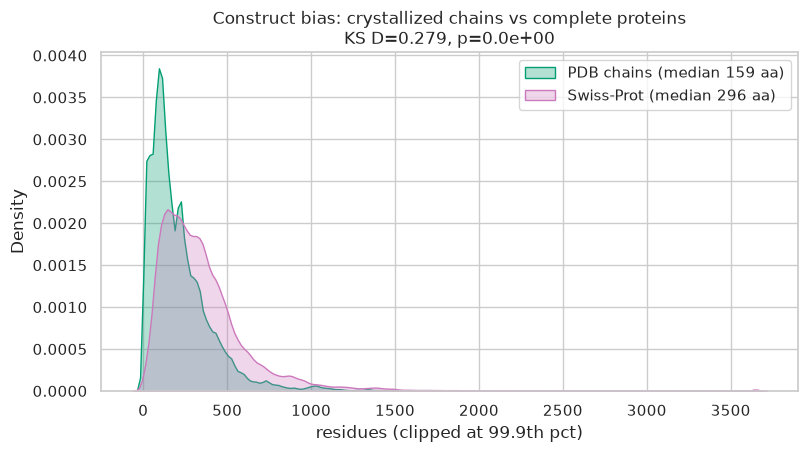

In [6]:
pdb_len = query_df('SELECT pro_len FROM pdb_chain_seq WHERE pro_len IS NOT NULL')
pdb_lens = pdb_len['pro_len'].astype(int)

ks_stat, ks_p = stats.ks_2samp(pdb_lens.to_numpy(), uni_lens.to_numpy())
mw_u, mw_p = stats.mannwhitneyu(pdb_lens, uni_lens, alternative='two-sided')
comparison = pd.DataFrame([
    {'source': 'pdb_chain_seq', 'n': len(pdb_lens),
     'mean': pdb_lens.mean(), 'std': pdb_lens.std(),
     'q25': pdb_lens.quantile(0.25), 'median': pdb_lens.median(),
     'q75': pdb_lens.quantile(0.75), 'q95': pdb_lens.quantile(0.95),
     'max': pdb_lens.max()},
    uni_summ.iloc[0].to_dict(),
])
tests = pd.DataFrame([
    {'test': 'kolmogorov-smirnov', 'statistic': ks_stat, 'p_value': ks_p},
    {'test': 'mann-whitney-u', 'statistic': mw_u, 'p_value': mw_p},
])
save_csv(comparison, 'protein_length_comparison')
save_csv(tests, 'protein_length_tests')

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.kdeplot(pdb_lens.clip(upper=uni_lens.quantile(0.999)), ax=ax,
            label=f'PDB chains (median {pdb_lens.median():.0f} aa)',
            color=PALETTE[2], fill=True, alpha=0.3)
sns.kdeplot(uni_lens.clip(upper=uni_lens.quantile(0.999)), ax=ax,
            label=f'Swiss-Prot (median {uni_lens.median():.0f} aa)',
            color=PALETTE[4], fill=True, alpha=0.3)
ax.set_xlabel('residues (clipped at 99.9th pct)')
ax.set_title('Construct bias: crystallized chains vs complete proteins\n'
             f'KS D={ks_stat:.3f}, p={ks_p:.1e}')
ax.legend()
save_fig(fig, 'protein_length_pdb_vs_uniprot')
print(tests.to_string(index=False))
comparison

## 5. Keywords - the functional vocabulary

`uniprot_keyword` holds the curated UniProt keyword vocabulary. The most
abundant keywords describe the functional core of the curated proteome
(compartment, catalytic activity, binding). This table is the basis for
downstream enrichment analysis against any protein list.

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_top_keywords.csv  shape=(40, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_top_keywords.png


,keyword,n_proteins,fraction_of_proteome
0,Reference proteome,376013,0.653364
1,Cytoplasm,169160,0.293934
2,Metal-binding,127307,0.221210
3,Membrane,119067,0.206892
4,Nucleotide-binding,102573,0.178232
5,Transferase,99575,0.173023
6,ATP-binding,83448,0.145000
7,Transmembrane,82112,0.142679
8,Transmembrane helix,80659,0.140154
9,Hydrolase,68323,0.118719


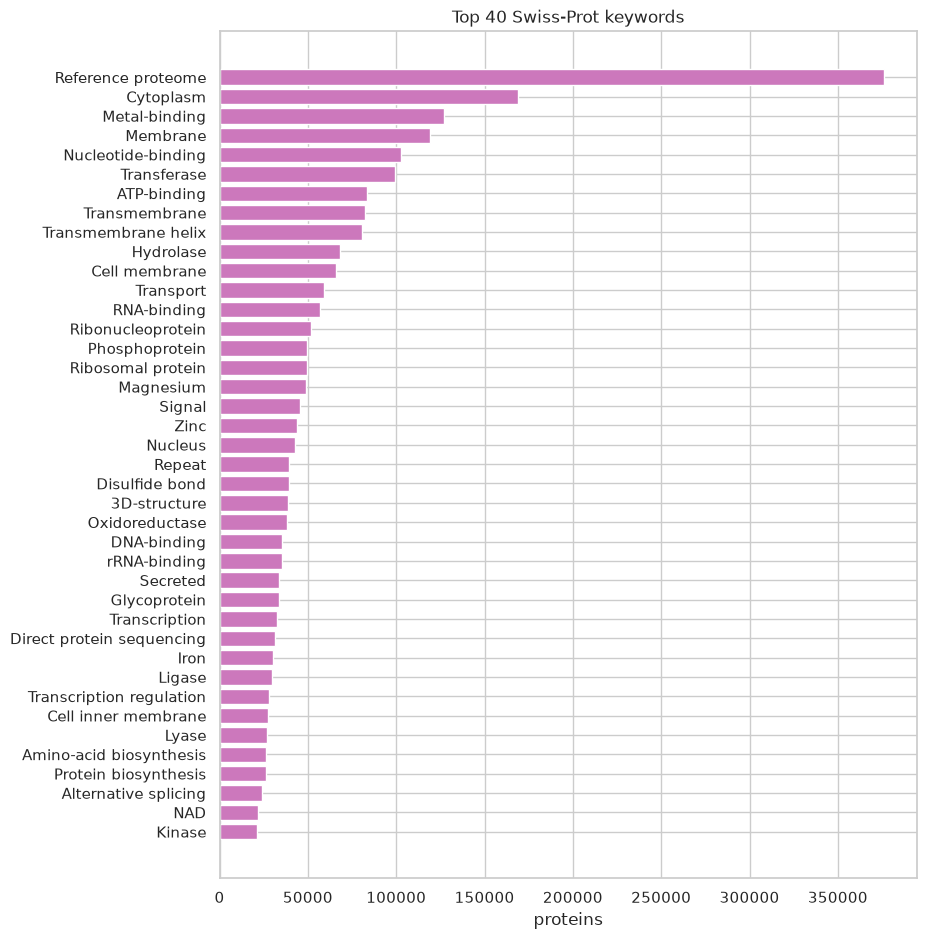

In [7]:
kw = query_df("""
    SELECT keyword, COUNT(DISTINCT uniprot_acc) AS n_proteins
    FROM uniprot_keyword
    WHERE keyword IS NOT NULL
    GROUP BY keyword
    ORDER BY n_proteins DESC
    LIMIT 40
""")
kw['n_proteins'] = kw['n_proteins'].astype(int)
kw['fraction_of_proteome'] = kw['n_proteins'] / total
save_csv(kw, 'uniprot_top_keywords')

fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(kw['keyword'].iloc[::-1], kw['n_proteins'].iloc[::-1], color=PALETTE[4])
ax.set_title('Top 40 Swiss-Prot keywords')
ax.set_xlabel('proteins')
save_fig(fig, 'uniprot_top_keywords')
kw.head(12)

## 6. Sequence features - type abundance and geometry

`uniprot_feature` stores feature annotations with sequence coordinates
(e.g. DOMAIN, HELIX, SIGNAL, MOD_RES). Aggregating feature types answers:

- which feature types dominate curated annotation,
- how long features of each type are on average - sanity-checking that
  structural elements match structural biology expectations
  (helix ~10 aa, strand ~5 aa, domain ~150-250 aa, signal peptide ~20 aa).

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_feature_stats.csv  shape=(30, 5)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_feature_types.png


,feature,n_features,n_proteins,mean_len_aa,sd_len_aa
0,BINDING,1309870,225232,2.82,3.14
1,CHAIN,573599,558128,364.10,340.51
2,HELIX,465333,35254,9.80,7.09
3,STRAND,414358,32736,6.76,2.96
4,TRANSMEM,386051,80896,22.08,1.89
5,REGION,330964,152202,73.36,111.20
6,MOD_RES,269415,75418,2.00,0.00
7,COMPBIAS,269138,93454,18.61,19.41
8,DOMAIN,220301,134351,135.14,92.29
9,ACT_SITE,181213,107646,2.00,0.00


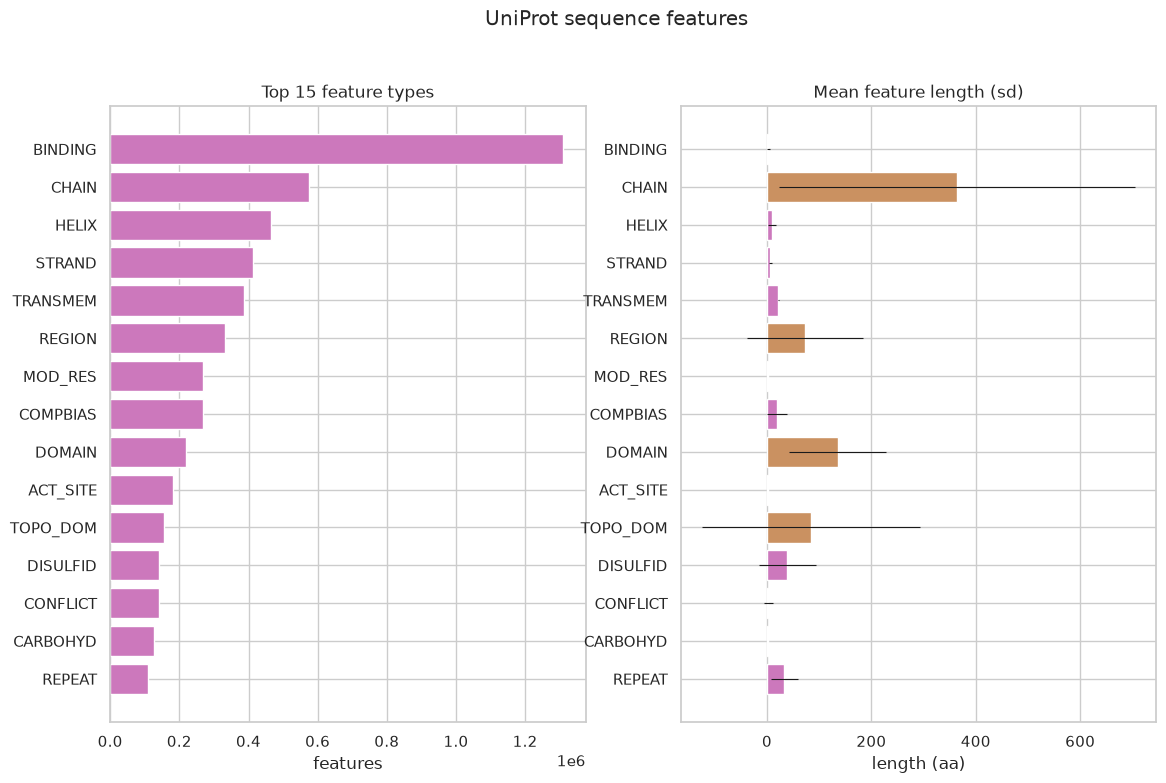

In [8]:
features = query_df("""
    SELECT feature,
           COUNT(*) AS n_features,
           COUNT(DISTINCT uniprot_acc) AS n_proteins,
           AVG(CAST(end AS UNSIGNED) - CAST(start AS UNSIGNED) + 1) AS mean_len_aa,
           STDDEV_POP(CAST(end AS UNSIGNED) - CAST(start AS UNSIGNED) + 1) AS sd_len_aa
    FROM uniprot_feature
    WHERE start REGEXP '^[0-9]+$' AND end REGEXP '^[0-9]+$'
    GROUP BY feature
    ORDER BY n_features DESC
    LIMIT 30
""")
for c in ('n_features', 'n_proteins'):
    features[c] = features[c].astype(int)
for c in ('mean_len_aa', 'sd_len_aa'):
    features[c] = features[c].astype(float).round(2)
save_csv(features, 'uniprot_feature_stats')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 8))
f10 = features.head(15).iloc[::-1]
axes[0].barh(f10['feature'], f10['n_features'], color=PALETTE[4])
axes[0].set_title('Top 15 feature types')
axes[0].set_xlabel('features')
fl = features.head(15).iloc[::-1]
colors = [PALETTE[4] if 3 <= l <= 40 else PALETTE[5] for l in fl['mean_len_aa']]
axes[1].barh(fl['feature'], fl['mean_len_aa'], xerr=fl['sd_len_aa'],
             color=colors, error_kw={'lw': 0.8})
axes[1].set_title('Mean feature length (sd)')
axes[1].set_xlabel('length (aa)')
fig.suptitle('UniProt sequence features', y=1.0)
save_fig(fig, 'uniprot_feature_types')
features

## 7. Cross-references - the annotation network

`uniprot_dbxrefs` links every entry to external resources (GO, InterPro, Pfam,
EMBL, PDB, AlphaFoldDB ...). Beyond raw counts, the **coverage fraction per
resource** (how many of the 575k curated entries point to that resource) is
biologically telling: it exposes the *structural coverage gap* - sequence and
function are broadly annotated, but experimental structure (PDB) covers only a
small slice, which predicted models (AlphaFoldDB) close.

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_dbxref_coverage.csv  shape=(171, 4)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_dbxref_coverage.png
total Swiss-Prot entries: 575,503


,db_name,n_links,n_proteins,coverage_fraction
0,GO,3372648,555469,0.9652
1,InterPro,2604071,558325,0.9702
2,EMBL,985153,562411,0.9773
3,PANTHER,965927,506395,0.8799
4,Pfam,883229,550811,0.9571
5,Gene3D,801455,479022,0.8324
6,SUPFAM,652991,462577,0.8038
7,RefSeq,568785,444709,0.7727
8,FunFam,559300,327988,0.5699
9,AlphaFoldDB,551806,551806,0.9588


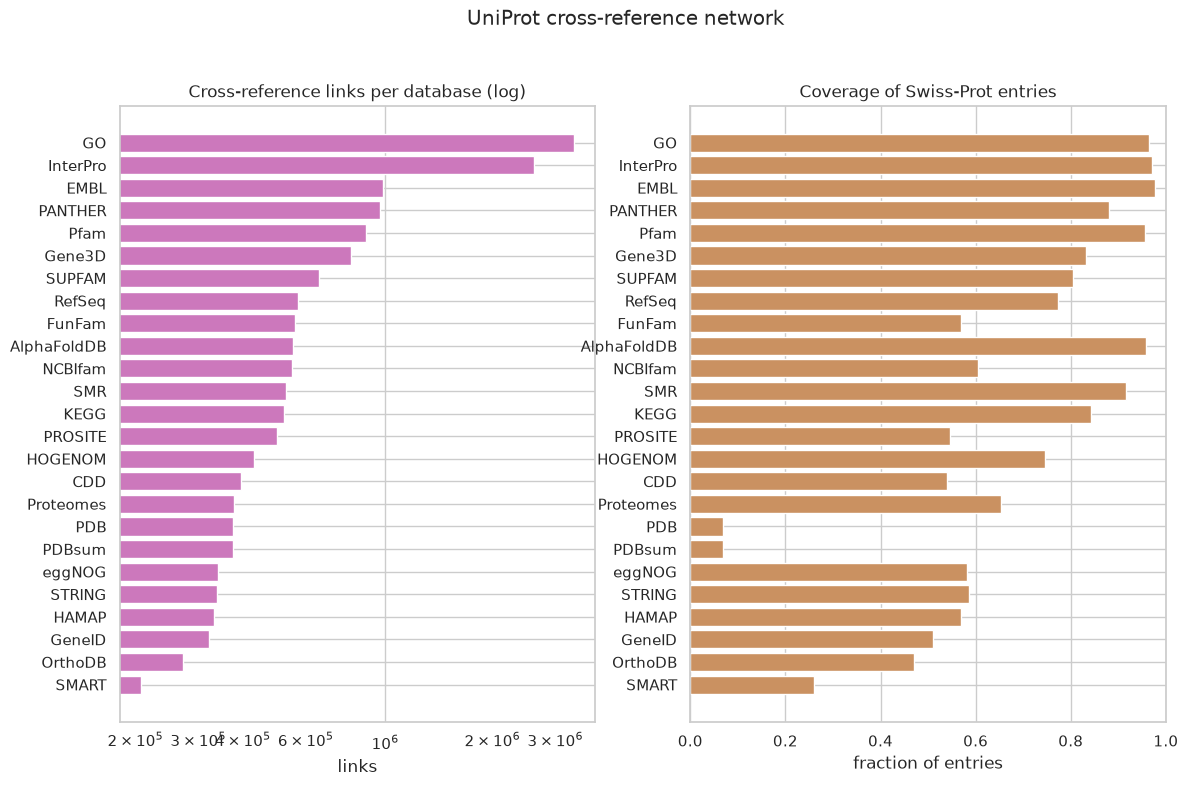

In [9]:
xrefs = query_df("""
    SELECT db_name,
           COUNT(*) AS n_links,
           COUNT(DISTINCT uniprot_acc) AS n_proteins
    FROM uniprot_dbxrefs
    WHERE db_name IS NOT NULL
    GROUP BY db_name
    ORDER BY n_links DESC
""")
xrefs['n_links'] = xrefs['n_links'].astype(int)
xrefs['n_proteins'] = xrefs['n_proteins'].astype(int)
xrefs['coverage_fraction'] = (xrefs['n_proteins'] / total).round(4)
save_csv(xrefs, 'uniprot_dbxref_coverage')

xt = xrefs.head(25).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 8))
axes[0].barh(xt['db_name'], xt['n_links'], color=PALETTE[4])
axes[0].set_xscale('log')
axes[0].set_title('Cross-reference links per database (log)')
axes[0].set_xlabel('links')
axes[1].barh(xt['db_name'], xt['coverage_fraction'], color=PALETTE[5])
axes[1].set_xlim(0, 1)
axes[1].set_title('Coverage of Swiss-Prot entries')
axes[1].set_xlabel('fraction of entries')
fig.suptitle('UniProt cross-reference network', y=1.0)
save_fig(fig, 'uniprot_dbxref_coverage')
print(f'total Swiss-Prot entries: {total:,}')
xrefs.head(12)

In [10]:
# the structural coverage gap in numbers
struct = xrefs[xrefs['db_name'].isin(['PDB', 'AlphaFoldDB', 'SMR', 'PDBsum'])][
    ['db_name', 'n_proteins', 'coverage_fraction']]
struct = struct.sort_values('n_proteins', ascending=False)
save_csv(struct, 'uniprot_structural_coverage')
struct

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_structural_coverage.csv  shape=(4, 3)


,db_name,n_proteins,coverage_fraction
9,AlphaFoldDB,551806,0.9588
11,SMR,527374,0.9164
17,PDB,39017,0.0678
18,PDBsum,39017,0.0678


**Interpretation.** GO/InterPro/Pfam annotate most of the proteome, while
experimental structures (PDB/PDBsum) cover only ~7% of curated entries.
AlphaFoldDB/SMR predictions cover >95%, i.e. structure *prediction* now
exceeds experimental coverage by more than an order of magnitude - the core
motivation for structure-aware pipelines such as this repo (PDB mirror +
AlphaFold comparisons).

## 8. Keyword co-occurrence - functional modules

Which keywords occur together on the same protein more often than expected?
A co-occurrence matrix over the top keywords highlights functional modules
(e.g. *Membrane + Transmembrane*, *Hydrolase + Metal-binding*). The matrix is
exported raw for downstream enrichment/network analysis.

saved table: /home/yuan/bio/bio_omics/doc/stats/uniprot_keyword_cooccurrence.csv  shape=(66, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/uniprot_keyword_cooccurrence.png


,Reference proteome,Cytoplasm,Metal-binding,Membrane,Nucleotide-binding,Transferase,ATP-binding,Transmembrane,Transmembrane helix,Hydrolase,Cell membrane,Transport
Reference proteome,0,113394,80959,83166,67111,64218,54627,56964,56194,44793,46581,37804
Cytoplasm,113394,0,45443,9195,53725,44726,43665,1445,1411,24692,5439,5926
Metal-binding,80959,45443,0,20969,32658,27166,23932,13351,13271,29312,9551,12558
Membrane,83166,9195,20969,0,15038,13265,12089,82112,80659,9257,65741,48963
Nucleotide-binding,67111,53725,32658,15038,0,31045,83448,5019,4978,15950,11215,9559
Transferase,64218,44726,27166,13265,31045,0,28977,10043,10021,3226,8060,777
ATP-binding,54627,43665,23932,12089,83448,28977,0,4534,4494,8425,9126,8757
Transmembrane,56964,1445,13351,82112,5019,10043,4534,0,80659,5548,43166,33298
Transmembrane helix,56194,1411,13271,80659,4978,10021,4494,80659,0,5493,43058,32448
Hydrolase,44793,24692,29312,9257,15950,3226,8425,5548,5493,0,5494,1195


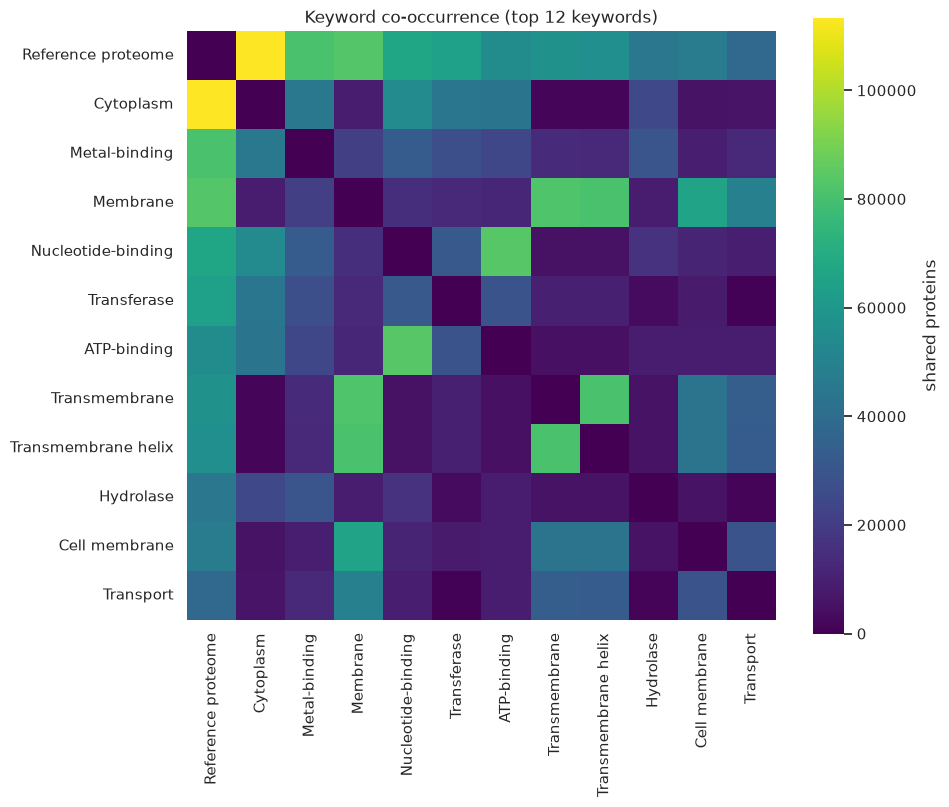

In [11]:
top_kw = kw.head(12)['keyword'].tolist()
quoted = ', '.join(f"'{k.replace(chr(39), '')}'" for k in top_kw)
cooc = query_df(f"""
    SELECT A.keyword AS kw_a, B.keyword AS kw_b, COUNT(*) AS n_pairs
    FROM uniprot_keyword A
    JOIN uniprot_keyword B
      ON A.uniprot_acc = B.uniprot_acc AND A.keyword < B.keyword
    WHERE A.keyword IN ({quoted}) AND B.keyword IN ({quoted})
    GROUP BY kw_a, kw_b
""")
save_csv(cooc, 'uniprot_keyword_cooccurrence')

mat = cooc.pivot(index='kw_a', columns='kw_b', values='n_pairs')
full = pd.DataFrame(0, index=top_kw, columns=top_kw, dtype=int)
for a in top_kw:
    for b in top_kw:
        if a == b:
            continue
        key = (a, b) if a < b else (b, a)
        if key[0] in mat.index and key[1] in mat.columns:
            v = mat.loc[key[0], key[1]]
            if pd.notna(v):
                full.loc[a, b] = full.loc[b, a] = int(v)
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(full, ax=ax, cmap='viridis', square=True,
            cbar_kws={'label': 'shared proteins'})
ax.set_title('Keyword co-occurrence (top 12 keywords)')
save_fig(fig, 'uniprot_keyword_cooccurrence')
full

## Summary

This notebook exported:

- figures: `uniprot_creation_trend`, `uniprot_top_organisms`,
  `uniprot_protein_length`, `protein_length_pdb_vs_uniprot`,
  `uniprot_top_keywords`, `uniprot_feature_types`, `uniprot_dbxref_coverage`,
  `uniprot_keyword_cooccurrence` -> `doc/figures/`
- statistical tables: inventory, yearly growth, organisms, length stats +
  PDB-vs-Swiss-Prot comparison/tests, keywords, feature stats, cross-reference
  coverage, structural coverage, co-occurrence -> `doc/stats/`

In [12]:
written = sorted(p.name for p in STAT_DIR.glob('uniprot_*.csv')) +           sorted(p.name for p in STAT_DIR.glob('protein_length*.csv'))
print('statistical tables ready for further analysis:')
for name in written:
    df = pd.read_csv(STAT_DIR / name)
    print(f'  {name:45s} shape={df.shape}')

statistical tables ready for further analysis:
  uniprot_creation_by_year.csv                  shape=(41, 3)
  uniprot_dbxref_coverage.csv                   shape=(171, 4)
  uniprot_feature_stats.csv                     shape=(30, 5)
  uniprot_keyword_cooccurrence.csv              shape=(66, 3)
  uniprot_length_stats.csv                      shape=(1, 9)
  uniprot_structural_coverage.csv               shape=(4, 3)
  uniprot_table_inventory.csv                   shape=(5, 2)
  uniprot_top_keywords.csv                      shape=(40, 3)
  uniprot_top_organisms.csv                     shape=(30, 3)
  protein_length_comparison.csv                 shape=(2, 9)
  protein_length_tests.csv                      shape=(2, 3)
